In [1]:
import matplotlib.pyplot as plt
import numpy as np

def draw_area(x,y,model):
  # 1. 그래프의 x,y 축의 범위 설정
  x_min,x_max = x[:,0].min()-1, x[:,0].max()+1
  y_min,y_max = x[:,1].min()-1, x[:,1].max()+1

  # 2. 만든 범위를 0.01 간격으로 촘촘한 값을 생성
  pos_x = np.arange(x_min,x_max,0.01)
  pos_y = np.arange(y_min,y_max,0.01)
  # print(f'pos X : {pos_x}')
  # print(f'pos Y : {pos_y}')

  # 3. 격자 형태로 x,y 배열을 만든다.
  xx,yy = np.meshgrid(pos_x, pos_y)

  # 4. 두 배열을 합쳐서 일렬로 만들어 준다.
  # 두 배열을 합칠때 각각 1차원 이어야 하는데 xx, yy 는 2차원이다.
  # 그래서 ravel() 함수를 통해 1차원으로 만든다.
  val = np.c_[xx.ravel(),yy.ravel()]
  # print(val) # [[x,y],[x,y],...]

  # 5. 이렇게 생성된 값으로 모델에 예측을 시킨다.
  z = model.predict(val)
  print(z)

  # 6. 영역을 그려준다.
  plt.scatter(x[:,0],x[:,1], c=y)
  plt.contourf(xx,yy,z.reshape(xx.shape),alpha=0.3)
  plt.show()

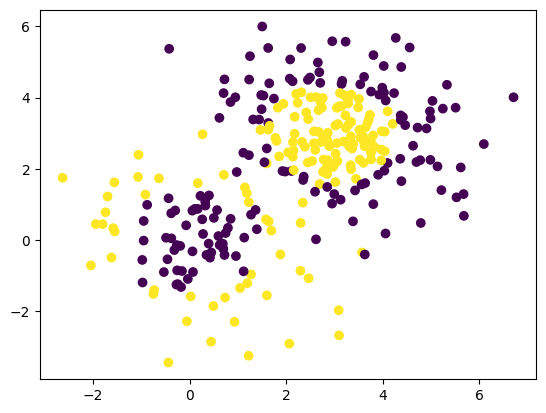

In [5]:
# 1. 데이터 호출
arr = np.load('/content/data/gaussian.npz')
x = arr['x']
y = arr['y']

# 2. 데이터 확인
plt.scatter(x[:,0],x[:,1], c=y)
plt.show()

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
# 3. 데이터 분할(상황에 따라서 생략하기도...)
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.3,random_state=55)

# 4. 모델 선택 -> 훈련
# Gradient 는 기본적으로 Tree Regression 을 사용한다.(잔차계산을 위해)
# learning_rate=0.1 : 학습률, 클수록 트리보정이 강해진다.(기본 0.1)
# max_depth=2 : 트리의 깊이
# n_estimators=9 : 진행할 트리 갯수(단계)
model = GradientBoostingClassifier(learning_rate=0.3, max_depth=3, n_estimators=9).fit(x_train,y_train)

print(f'train score : {model.score(x_train,y_train)}')
print(f'test score : {model.score(x_test,y_test)}')


train score : 0.9
test score : 0.8555555555555555


[-0.41566344 -0.41566344 -0.41566344 ... -2.16494845 -2.16494845
 -2.16494845]


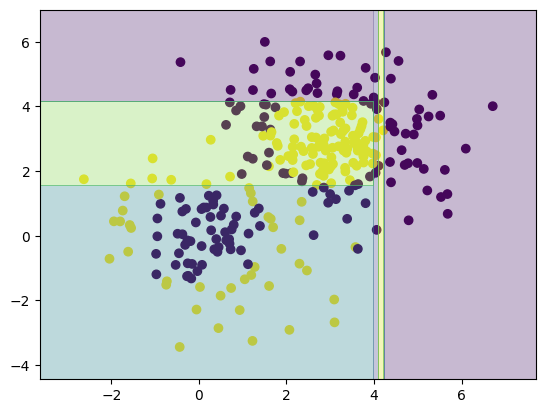

[-0.35558254 -0.35558254 -0.35558254 ... -1.66866666 -1.66866666
 -1.66866666]


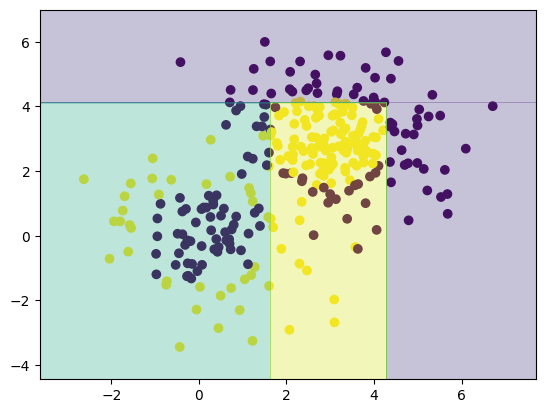

[ 2.08187641  2.08187641  2.08187641 ... -1.12549757 -1.12549757
 -1.12549757]


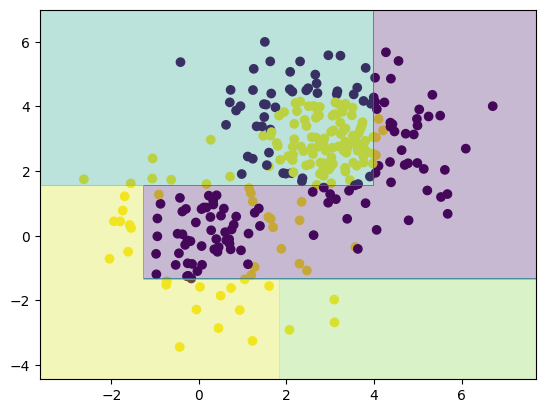

[ 1.57933987  1.57933987  1.57933987 ... -1.36106349 -1.36106349
 -1.36106349]


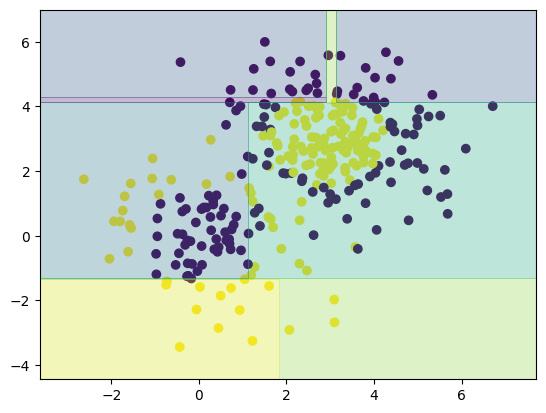

[ 1.72970762  1.72970762  1.72970762 ... -0.99760876 -0.99760876
 -0.99760876]


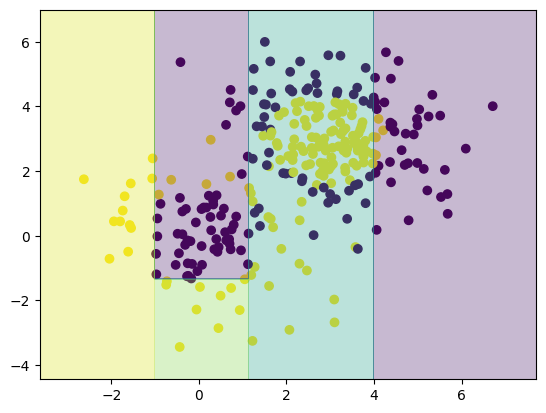

[ 1.43429831  1.43429831  1.43429831 ... -1.29427275 -1.29427275
 -1.29427275]


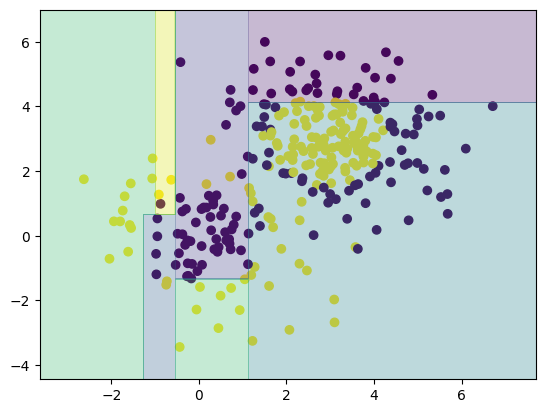

[-0.09742828 -0.09742828 -0.09742828 ... -1.23277926 -1.23277926
 -1.23277926]


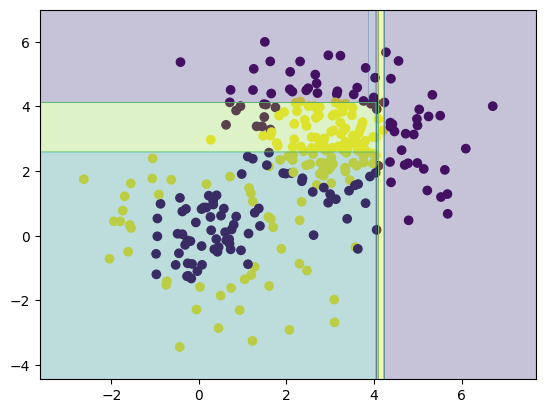

[0.87519796 0.87519796 0.87519796 ... 0.13104946 0.13104946 0.13104946]


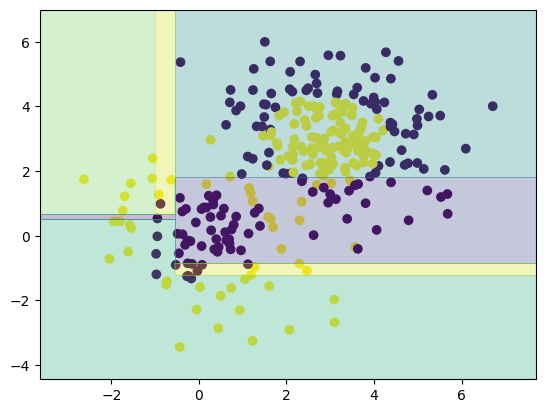

[ 0.14143159  0.14143159  0.14143159 ... -1.1638496  -1.1638496
 -1.1638496 ]


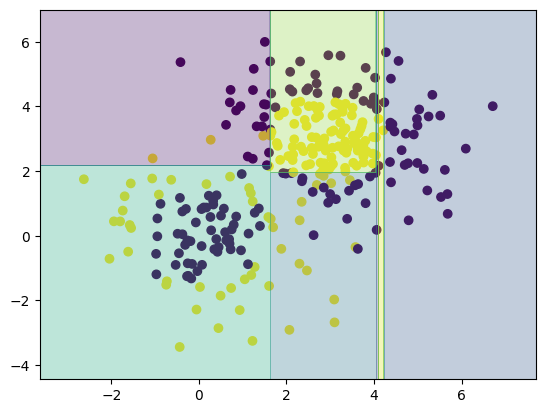

[1 1 1 ... 0 0 0]


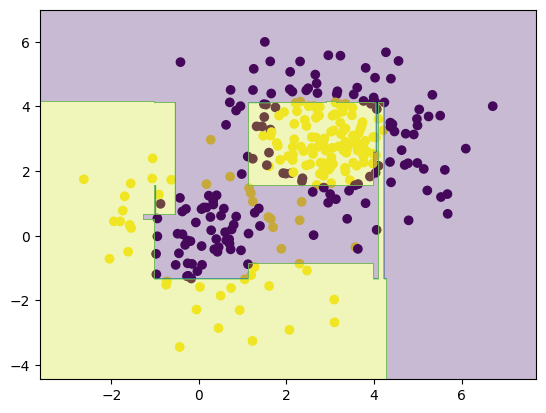

In [21]:
for m in model.estimators_:
  draw_area(x,y,m[0])
draw_area(x,y,model)